# 30 · 부피를 보정하며 학습하는 Normalizing Flow

📎 **이번 질문** · 동그란 Gaussian 잡음을 휘어진 자료 모양으로 바꾸면서, 각 점의 밀도도 정확히 계산할 수 있을까요?

12번에서는 Gaussian 잡음에 선형 변환을 적용했습니다. 여기서는 역변환을 쉽게 계산하는 비선형 변환을 여러 번 연결합니다. 데이터를 표준정규 좌표로 보내 로그 우도를 학습하고, 새 표준정규 잡음을 반대 방향으로 보내 생성합니다. **밀도 계산 방향과 생성 방향을 따로 적는 것**이 출발점입니다.

- 준비물: [11 선형대수](../02_연결/11_linear_algebra.ipynb)의 행 저장·행렬곱, [12 Gaussian](../02_연결/12_gaussian_information.ipynb)의 행렬식·로그 밀도·Gaussian 생성, [27 Monte Carlo](27_monte_carlo_gradients.ipynb)의 적분과 표본 평균, [03 MLP](../00_기초/03_perceptron_to_mlp.ipynb)의 연쇄법칙, [04 optimizer](../00_기초/04_optimizers.ipynb)의 Adam.
- 도착점: affine coupling의 순·역변환, log Jacobian, 전체 backward, 실제 2D 우도 학습·독립 평가·샘플 생성을 구현합니다.
- NumPy·Matplotlib·CPU float64만 사용합니다. 다른 노트북의 실행 상태나 외부 데이터 다운로드는 필요하지 않습니다.

> **용어**
>
> - **가역(invertible) 변환**은 출력 하나에서 원래 입력을 하나로 되찾을 수 있는 변환입니다.
> - **잠재변수(latent variable) z**는 여기서 밀도를 아는 표준정규 좌표입니다.
> - **normalizing flow**는 가역 변환을 합성해 단순한 base 분포와 복잡한 데이터 분포를 연결하는 모델입니다.
> - **정확한 밀도(exact density)**는 추가 정규화 상수 추정이나 우도 하한 없이 정규화된 밀도 식을 계산한다는 뜻입니다. 부동소수점 오차나 모델 오차가 없다는 뜻은 아닙니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 설명·수식·구현 | 변환 방향과 축을 써 봅니다 |
| 🔍 확인 | 그림·검산·평가 | 항등식과 수치 근사를 구분합니다 |
| 📎 참고 | 용어·코드·연결 | 처음 나온 표현을 바로 풀이합니다 |
| ✏️ 연습 | 핵심 한두 줄 | 정답을 접고 작은 값으로 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 데이터→잠재 $z=f(x)$에서는 $\log p_X(x)=\log p_Z(f(x))+\log|\det J_f(x)|$입니다. 생성 $x=f^{-1}(z)$에서는 inverse logdet를 **뺍니다**.
2. 한 좌표를 유지하는 coupling은 삼각 Jacobian을 갖습니다. 유지 좌표가 변환할 좌표의 scale·shift를 정하며, 좌표 swap을 사이에 넣어 두 축을 모두 바꿉니다.
3. 전체 우도 미분에는 잠재 제곱 크기와 logdet의 기여가 모두 필요합니다. 적분 격자의 해상도 오차, 상자 밖 확률, 생성 표본의 Monte Carlo 오차는 별개입니다.

| 기호 | shape | 뜻 |
|---|---|---|
| $X,Y,Z$ | $(N,2)$ | 행마다 한 2D 관측·중간 좌표·잠재 좌표 |
| $a,b,s,t$ | $(N,1)$ | 유지 좌표·바꿀 좌표·log scale·shift |
| $H,U$ | $(N,F)$ / $(N,2)$ | conditioner의 은닉 특징 / s,t의 원점수 |
| local·total logdet | $(N,)$ | 관측마다 한 Jacobian 로그 절댓값 |
| NLL | scalar | 관측별 음의 로그 우도의 평균 |

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/flow_plots.py)

In [1]:
# 준비 셀: 공통 검산·그림 부품을 불러옵니다.
import sys
from pathlib import Path
from math import erf
from time import perf_counter
import numpy as np
project_root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.flow_plots import (
    plot_affine_volume,plot_coupling_map,plot_flow_stages,plot_training_plan,
    plot_nll_history,plot_fitted_density,plot_quadrature_cells,
    plot_generation_diagnostics,plot_mass_checks,
)
setup_plots()
print('NumPy',np.__version__,'· 데이터→z가 forward · z→데이터가 inverse')

NumPy 2.4.6 · 데이터→z가 forward · z→데이터가 inverse


## 🔑 1. 늘어난 구간에서는 밀도 높이가 낮아집니다

**이 절에서 가져갈 것:** 확률 질량을 보존하도록 Jacobian의 절댓값으로 밀도를 보정합니다.

표준정규 센서값 z를 두 배 늘리고 1만큼 옮겨 $x=2z+1$로 표시합니다. 같은 작은 구간의 확률은 그대로인데 구간 폭은 두 배입니다. 그러므로 단위 길이당 밀도는 절반이어야 합니다.

일반적인 $x=cz+d$, $c\ne0$에서

$$z=(x-d)/c,\qquad p_X(x)=\frac{p_Z((x-d)/c)}{|c|},\qquad
\log p_X(x)=\log p_Z(z)-\log|c|.$$

부호가 음수인 c는 방향을 뒤집지만 음의 확률을 만들지 않습니다. 2D 선형 생성 $x=Az+d$는 면적을 $|\det A|$배 바꾸므로 밀도를 그만큼 나눕니다. 그림의 $A=\left[\begin{smallmatrix}2&1\\0&1\end{smallmatrix}\right]$는 면적을 두 배로 만듭니다.

일반적인 매끄러운 가역 변환 $z=f(x)$의 **데이터→잠재** 방향은

$$p_X(x)=p_Z(f(x))|\det J_f(x)|,\qquad (J_f)_{ij}=\frac{\partial f_i}{\partial x_j}.$$

$J_f$는 작은 x 구간을 z 구간으로 보내는 선형 근사입니다. 이것이 **변수변환 공식**입니다. 1D의 $J_f=1/c$와 생성 방향의 $J_{f^{-1}}=c$를 혼동하지 않습니다.

> **용어** · **밀도(density)**는 작은 구간의 확률을 그 구간 폭·면적으로 나눈 값입니다. **Jacobian**은 출력 좌표별 입력 미분을 행렬로 모은 것입니다. **행렬식(determinant)**의 절댓값은 국소 부피 배율입니다. **logdet**는 여기서 언제나 $\log|\det J|$를 뜻합니다.

> **코드** · `np.column_stack([a,b])`는 같은 길이의 두 배열을 열로 붙입니다. `vertices @ A.T`는 행마다 저장한 점에 열벡터 식 $Az$를 적용합니다. `np.linalg.slogdet(A)`는 행렬식의 부호와 로그 절댓값을 따로 돌려줍니다.

In [2]:
affine_z = np.array([-1.,0.,1.])
affine_x = 2*affine_z+1
affine_pz = np.exp(-.5*affine_z**2)/np.sqrt(2*np.pi)
affine_px = affine_pz/2
affine_base_table = np.column_stack([affine_z,affine_pz])
affine_data_table = np.column_stack([affine_x,affine_px])
affine_A = np.array([[2.,1.],[0.,1.]])
base_vertices = np.array([[0.,0.],[1.,0.],[1.,1.],[0.,1.],[0.,0.]])
data_vertices = base_vertices @ affine_A.T

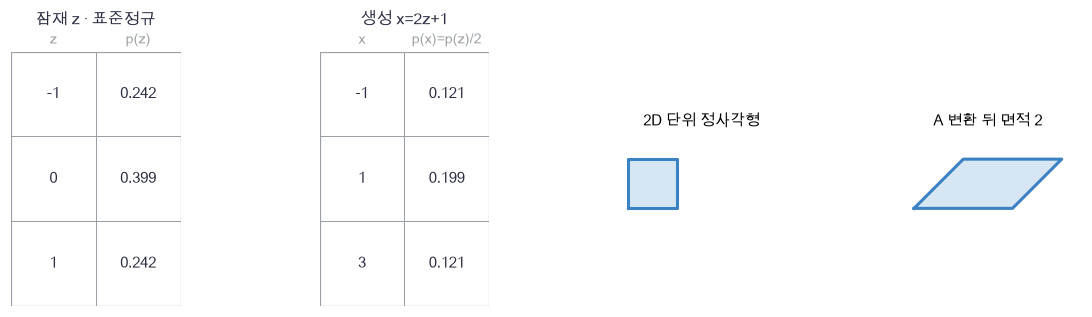

In [3]:
plot_affine_volume(affine_base_table,affine_data_table,base_vertices,data_vertices)

🔍 **확인** · $z=0$의 밀도는 $1/\sqrt{2\pi}$이고 대응하는 $x=1$의 밀도는 그 절반입니다. 점 하나의 확률이 절반이 되었다는 뜻이 아니라 구간 폭이 늘어난 만큼 **밀도 높이**가 낮아졌다는 뜻입니다. 마지막 두 그림은 같은 확률이 담긴 면적의 배율을 보여 줍니다.

In [4]:
def affine_density_loop(x,scale,shift):
    """생성 x=scale*z+shift의 1D 밀도를 반복문으로 구합니다. x:(N,) → density:(N,)."""
    assert scale != 0., '가역 변환의 scale은0이 아니어야 합니다'
    density = np.zeros_like(x,dtype=float)
    for i in range(len(x)):
        z = (x[i]-shift)/scale
        density[i] = np.exp(-.5*z*z)/np.sqrt(2*np.pi)/abs(scale)
    return density

In [5]:
def affine_logpdf(x,scale,shift):
    """x→z=(x-shift)/scale와 log|dz/dx|를 더합니다. x:(N,) → log density:(N,)."""
    assert scale != 0., '가역 변환의 scale은0이 아니어야 합니다'
    z = (x-shift)/scale
    return -.5*(z*z+np.log(2*np.pi))-np.log(abs(scale))

In [6]:
# 쓰는 것: affine_A (1절) · affine_px (1절) · affine_x (1절)
np.testing.assert_allclose(affine_density_loop(affine_x,2.,1.),affine_px)  # 검산: 손계산과 반복문
np.testing.assert_allclose(np.exp(affine_logpdf(affine_x,2.,1.)),affine_px)  # 검산: 손계산과 벡터화 log밀도
np.testing.assert_allclose(affine_density_loop(affine_x,-2.,1.),affine_px)  # 검산: 표준정규 대칭성과 음수 scale의 절댓값
np.testing.assert_allclose(np.linalg.det(affine_A),2.)  # 검산: 2*1-1*0의 면적 배율
np.testing.assert_allclose(np.linalg.slogdet(np.linalg.inv(affine_A))[1],-np.log(2))  # 검산: inverse logdet의 부호
integral_width = 32/2000
integral_x = -15+(np.arange(2000)+.5)*integral_width
integral_1d = np.exp(affine_logpdf(integral_x,2.,1.)).sum()*integral_width
np.testing.assert_allclose(integral_1d,1.,atol=1e-12)  # 검산: 잠재 ±8에 해당하는 넓은 구간의 질량
print('1D 손계산·반복문·벡터화·부호·밀도 적분 통과:',integral_1d)

1D 손계산·반복문·벡터화·부호·밀도 적분 통과: 0.9999999999999988


### ✏️ 연습 1 · 생성 scale이 음수여도 밀도는 양수

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

생성 방향 `x=scale*z+shift`에서 해당 z의 밀도 `base_density`가 주어졌습니다. x의 밀도를 한 줄로 계산하세요.

In [7]:
def exercise_affine_density(base_density,scale):
    """연습 1: 생성 부피 배율의 절댓값으로 밀도를 나눕니다."""
    assert scale != 0., '가역 scale이 필요합니다'
    ### 구현할 내용: base density / |scale|
    raise NotImplementedError
    return density

In [8]:
def check_affine_density(candidate):
    """늘림·방향 반전·축소의 밀도를 손계산합니다."""
    np.testing.assert_allclose(candidate(np.array([.2,.4]),2.),[.1,.2])  # 검산: 폭2배→높이절반
    np.testing.assert_allclose(candidate(np.array([.2,.4]),-2.),[.1,.2])  # 검산: 부호 반전은 확률 음수 아님
    np.testing.assert_allclose(candidate(np.array([.2]),.5),[.4])  # 검산: 폭절반→높이2배
    print('affine 밀도: 손계산과 일치합니다.')

run_check(check_affine_density,exercise_affine_density,hint='density = base_density/abs(scale)')

☐ exercise_affine_density: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: density = base_density/abs(scale)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
density = base_density/abs(scale)
```

</details>

## 🔑 2. 한 좌표를 남겨 두면 역변환이 쉬워집니다

**이 절에서 가져갈 것:** affine coupling의 데이터→잠재·역방향과 삼각 Jacobian을 같은 식으로 확인합니다.

두 센서 좌표 중 a를 그대로 두고 b만 바꿉니다. 그대로 남긴 a로 scale과 shift를 계산하면, 역변환 때에도 같은 a를 읽을 수 있습니다.

$$H=\tanh(aW_1+b_1),\quad U=HW_2+b_2,\quad s=.8\tanh(U_0),\quad t=U_1,$$
$$\underbrace{y_a=a,\quad y_b=(b-t(a))e^{-s(a)}}_{\text{데이터→잠재 방향의 한 층}},\qquad
\underbrace{a=y_a,\quad b=y_b e^{s(a)}+t(a)}_{\text{생성 방향의 역변환}}.$$

$W_1:(1,F)$, $W_2:(F,2)$입니다. 모든 유한 파라미터에서 $-.8<s<.8$이고 $e^s>0$이므로 b를 되찾을 수 있습니다. 조건을 만드는 신경망 자체는 가역일 필요가 없습니다.

$$J_f=\begin{bmatrix}1&0\\e^{-s}[-t'-(b-t)s']&e^{-s}\end{bmatrix},\quad
\log|\det J_f|=-s,\quad \log|\det J_{f^{-1}}|=+s.$$

s와 t의 미분이 복잡해도 Jacobian이 삼각형이라 행렬식에는 대각 성분만 필요합니다. 다만 **학습 미분에는 s,t의 전체 계산 경로가 필요**합니다. 이 구조는 [Dinh 외, Real NVP](https://arxiv.org/abs/1605.08803)의 affine coupling을 2D·작은 tanh 신경망으로 줄인 예제입니다. 원 논문의 이미지 모델 전체를 재현하지 않습니다.

> **용어** · **affine coupling**은 입력 일부가 나머지 부분의 이동·배율을 결정하는 가역 층입니다. **conditioner**는 여기서 a를 받아 s,t를 만드는 신경망입니다. **bounded scaling**은 $s=.8\tanh(U_0)$처럼 log scale의 범위를 제한하는 선택입니다.

> **코드** · `X[:,:1]`은 첫 열을 `(N,1)`로 유지하고 `X[:,0]`은 `(N,)`로 줄입니다. `np.concatenate([a,b],axis=1)`은 두 좌표 열을 붙입니다. `np.random.default_rng(seed)`는 용도별 독립 난수 상태를 만듭니다. 사전 `parameters['W1']`처럼 각 층의 배열을 이름으로 구분합니다.

In [9]:
coupling_X = np.array([[-1.,.5],[0.,-.5],[1.,1.]])
coupling_parameters = {'W1':np.array([[.7,-.4]]),'b1':np.array([.1,.2]),'W2':np.array([[.3,.5],[-.2,.4]]),'b2':np.array([.05,-.1])}
coupling_a,coupling_b = coupling_X[:,:1],coupling_X[:,1:2]
coupling_H = np.tanh(coupling_a @ coupling_parameters['W1']+coupling_parameters['b1'])
coupling_U = coupling_H @ coupling_parameters['W2']+coupling_parameters['b2']
coupling_s = .8*np.tanh(coupling_U[:,:1])
coupling_t = coupling_U[:,1:2]
coupling_Y = np.concatenate([coupling_a,(coupling_b-coupling_t)*np.exp(-coupling_s)],axis=1)
coupling_dU_da = ((1-coupling_H**2)*coupling_parameters['W1']) @ coupling_parameters['W2']
coupling_ds_da = .8*(1-np.tanh(coupling_U[:,0])**2)*coupling_dU_da[:,0]
coupling_dt_da = coupling_dU_da[:,1]
coupling_J = np.array([[1.,0.],[np.exp(-coupling_s[1,0])*(-coupling_dt_da[1]-(coupling_b[1,0]-coupling_t[1,0])*coupling_ds_da[1]),np.exp(-coupling_s[1,0])]])
coupling_st = np.concatenate([coupling_s,coupling_t],axis=1)

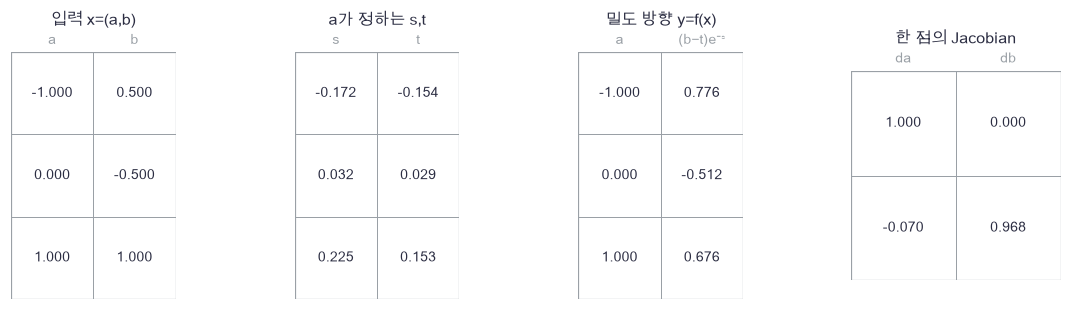

In [10]:
plot_coupling_map(coupling_X,coupling_st,coupling_Y,coupling_J)

🔍 **확인** · 첫 좌표 a는 그대로이고 두 번째 좌표만 바뀝니다. 마지막 Jacobian은 **가운데 관측 하나**에서 계산했습니다. 오른쪽 위가 0이므로 determinant는 오른쪽 아래의 $e^{-s}$입니다. 이 점의 inverse logdet는 반대 부호입니다.

In [11]:
def init_coupling(rng,hidden=12):
    """조건부 s,t를 만드는 tanh MLP. 입력1→hidden→출력2, near-identity 초기값."""
    return {'W1':rng.normal(0,.5,(1,hidden)), 'b1':rng.normal(0,.1,hidden),
            'W2':rng.normal(0,.05,(hidden,2)), 'b2':np.zeros(2)}

In [12]:
def conditioner(a,parameters):
    """유지 좌표 a로 s=.8*tanh(u0), t=u1을 만듭니다. a:(N,1) → s,t:(N,1), cache."""
    H = np.tanh(a @ parameters['W1']+parameters['b1'])
    U = H @ parameters['W2']+parameters['b2']
    bounded = np.tanh(U[:,:1])
    scale,shift = .8*bounded,U[:,1:2]
    return scale,shift,(a,H,bounded,parameters)

In [13]:
def coupling_forward(X,parameters):
    """밀도 방향 x→y: y0=a, y1=(b-t)*exp(-s). X:(N,2) → Y, logabsdet:(N,), cache."""
    a,b = X[:,:1],X[:,1:2]
    scale,shift,network_cache = conditioner(a,parameters)
    transformed = (b-shift)*np.exp(-scale)
    Y = np.concatenate([a,transformed],axis=1)
    return Y,-scale[:,0],(transformed,scale,network_cache)

In [14]:
def coupling_inverse(Y,parameters):
    """생성 방향 y→x: b=y1*exp(s)+t. Y:(N,2) → X, inverse logabsdet:(N,)."""
    a = Y[:,:1]
    scale,shift,_ = conditioner(a,parameters)
    b = Y[:,1:2]*np.exp(scale)+shift
    return np.concatenate([a,b],axis=1),scale[:,0]

In [15]:
# 쓰는 것: coupling_J (2절) · coupling_X (2절) · coupling_Y (2절) · coupling_parameters (2절) · coupling_s (2절)
actual_coupling_Y,actual_coupling_logdet,_ = coupling_forward(coupling_X,coupling_parameters)
np.testing.assert_allclose(actual_coupling_Y,coupling_Y)  # 검산: 그림의 직접 계산과 구현
recovered_coupling_X,inverse_coupling_logdet = coupling_inverse(actual_coupling_Y,coupling_parameters)
np.testing.assert_allclose(recovered_coupling_X,coupling_X,atol=1e-12)  # 검산: x→y→x 왕복
np.testing.assert_allclose(actual_coupling_logdet+inverse_coupling_logdet,0.,atol=1e-12)  # 검산: 같은 대응점의 logdet 상쇄
np.testing.assert_allclose(np.linalg.slogdet(coupling_J)[1],actual_coupling_logdet[1])  # 검산: 삼각 Jacobian logabsdet=-s
assert np.all(np.abs(coupling_s)<.8), 'log scale은 지정한 범위 안이어야 합니다'
print('그림·coupling 왕복·삼각 logdet 검산 통과')

그림·coupling 왕복·삼각 logdet 검산 통과


### ✏️ 연습 2 · 생성 방향으로 b를 되찾기

coupling 출력의 두 번째 좌표 `y_b`와, 유지 좌표에서 계산한 `s,t`가 주어집니다. 원래 b를 한 줄로 되찾으세요.

In [16]:
def exercise_inverse_coupling(y_b,s,t):
    """연습 2: data→latent의 반대 방향 b=y_b*exp(s)+t. 배열 shape는 모두 같음."""
    ### 구현할 내용: 축소를 되돌린 뒤 shift 더하기
    raise NotImplementedError
    return b

In [17]:
def check_inverse_coupling(candidate):
    """exp(log2)=2인 값과 log scale0을 손계산합니다."""
    actual = candidate(np.array([2.,-1.]),np.array([np.log(2),0.]),np.array([1.,3.]))
    np.testing.assert_allclose(actual,[5.,2.])  # 검산: 2*2+1, -1+3
    print('coupling inverse: 손계산과 일치합니다.')

run_check(check_inverse_coupling,exercise_inverse_coupling,hint='b = y_b*np.exp(s)+t')

☐ exercise_inverse_coupling: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: b = y_b*np.exp(s)+t


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
b = y_b*np.exp(s)+t
```

</details>

## 🔑 3. 층을 합치고 부피 항까지 역전파합니다

**이 절에서 가져갈 것:** coupling과 swap의 합성에서 logdet를 더하고, 잠재 값과 logdet 양쪽 경로를 미분합니다.

한 층은 a를 그대로 두었습니다. 다음 층 앞에서 좌표 둘을 바꾸면 앞서 유지한 좌표도 변환할 수 있습니다. 아래 모델은 **coupling 뒤 swap**을 네 번 반복합니다. swap은 행렬식이 −1이지만 절댓값은 1이므로 logdet 기여는 0입니다.

$$z=f_L\circ\cdots\circ f_1(x),\quad \ell(x)=\sum_{l=1}^L\log|\det J_{f_l}|,\quad
\log p_X(x)=-\tfrac12\|z\|^2-\log(2\pi)+\ell(x).$$

2차원이므로 base 정규화 상수는 $-\log(2\pi)$입니다. 관측 N개의 평균 음의 로그 우도는

$$L=\frac1N\sum_n\left[\tfrac12\|z_n\|^2+\log(2\pi)-\ell_n\right],\quad
\frac{\partial L}{\partial z}=z/N,\quad \frac{\partial L}{\partial\ell_n}=-1/N.$$

잠재 점만 원점으로 보내는 것으로는 충분하지 않습니다. 그렇게 압축한 부피의 logdet도 손실에 함께 들어갑니다.

한 coupling의 출력 기울기 $G=(G_a,G_b)$, local logdet의 기울기 $\lambda$에서

$$db=G_b e^{-s},\quad dt=-G_b e^{-s},\quad ds=-G_b y_b-\lambda,$$
$$dU_0=ds\cdot.8(1-\tanh^2 U_0),\quad dU_1=dt,\quad
 dH=(dU W_2^\top)\odot(1-H^2),$$
$$dW_2=H^\top dU,\quad db_2=\sum_n dU_n,\quad dW_1=a^\top dH,\quad db_1=\sum_n dH_n,\quad
da=G_a+dH W_1^\top.$$

여기서 dH는 tanh **입력**까지 미분한 중간 배열 이름입니다. 마지막 식은 유지 좌표의 직접 경로와 conditioner를 지나는 기여를 더합니다. swap의 backward도 같은 좌표 교환입니다. 역변환은 마지막 층부터 **swap을 먼저 되돌린 뒤 coupling inverse**를 적용합니다.

> **용어** · **합성(composition)**은 한 함수의 출력을 다음 함수의 입력에 넣는 것입니다. **음의 로그 우도(NLL)**는 관측의 로그 밀도에 마이너스를 붙인 손실입니다. **상류 기울기(upstream)**는 현재 연산의 출력으로 들어온 손실 미분입니다.

> **코드** · `X[:,::-1]`은 두 좌표 열의 순서를 뒤집습니다. `reversed(layers)`는 층을 마지막부터 읽습니다. `[function(...) for ...]`는 각 층의 독립 결과를 목록에 모읍니다. `enumerate`는 항목과 그 번호를 함께 줍니다.

In [18]:
# 쓰는 것: coupling_forward (2절) · init_coupling (2절)
diagram_rng = np.random.default_rng(309)
diagram_axis = np.linspace(-2,2,80)
diagram_X = np.column_stack([diagram_axis,.4*diagram_axis**2-.6+diagram_rng.normal(0,.12,80)])
diagram_parameters = [init_coupling(diagram_rng,3) for _ in range(4)]
for layer in diagram_parameters:
    layer['W2'] *= 5
diagram_stages = [diagram_X]
diagram_logdet = np.zeros(len(diagram_X))
for layer in diagram_parameters:
    diagram_next,diagram_local,_ = coupling_forward(diagram_stages[-1],layer)
    diagram_stages.append(diagram_next[:,::-1])
    diagram_logdet += diagram_local
diagram_labels = ['데이터 x','coupling+swap 1','coupling+swap 2','coupling+swap 3','예시 잠재 z']

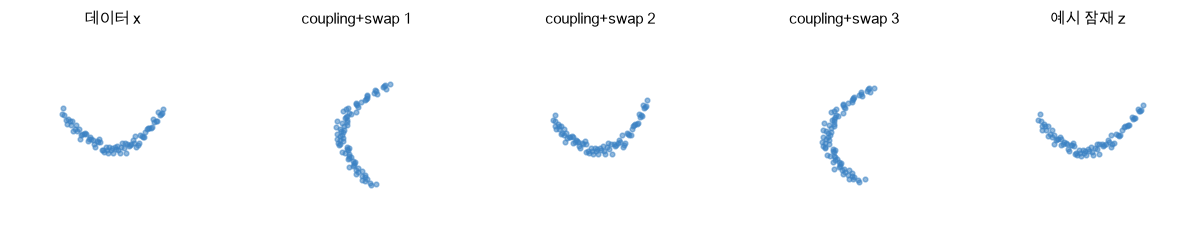

In [19]:
plot_flow_stages(diagram_stages,diagram_labels)

🔍 **확인** · 같은 점들이 각 변환을 따라 이동합니다. 모양을 보이기 위한 미학습 파라미터이므로 마지막 구름이 표준정규처럼 보일 필요는 없습니다. 모든 패널의 표시 범위는 두 축 ±4입니다. 아래 전체 forward가 그림에서 층별로 계산한 좌표·logdet와 같은지 대조합니다.

In [20]:
def coupling_backward(G,dlogdet,cache):
    """Y와 local logabsdet 양쪽 upstream을 미분합니다. G:(N,2), dlogdet:(N,) → dX, gradients."""
    transformed,scale,network_cache = cache
    a,H,bounded,parameters = network_cache
    # 1. y1=(b-t)e^-s와 logdet=-s의 두 기여를 합칩니다.
    db = G[:,1:2]*np.exp(-scale)
    dshift = -db
    dscale = -G[:,1:2]*transformed-dlogdet[:,None]
    dU = np.concatenate([dscale*.8*(1-bounded**2),dshift],axis=1)
    # 2. conditioner를 거슬러 유지 좌표 a의 직접 경로와 합칩니다.
    gradients = {'W2':H.T@dU,'b2':dU.sum(axis=0)}
    dH = (dU @ parameters['W2'].T)*(1-H**2)
    gradients['W1'],gradients['b1'] = a.T@dH,dH.sum(axis=0)
    da = G[:,:1]+dH @ parameters['W1'].T
    return np.concatenate([da,db],axis=1),gradients

In [21]:
def init_flow(seed=300,layers=4,hidden=12):
    """여러 coupling의 독립 파라미터 목록을 만듭니다. swap은 학습 파라미터가 없습니다."""
    # 쓰는 것: init_coupling (2절)
    rng = np.random.default_rng(seed)
    return [init_coupling(rng,hidden) for _ in range(layers)]

In [22]:
def flow_forward(X,parameters):
    """데이터→잠재 방향: coupling 뒤마다 두 좌표를 swap합니다. → Z:(N,2), total logdet:(N,), caches."""
    # 쓰는 것: coupling_forward (2절)
    current = X
    logdet = np.zeros(len(X))
    caches = []
    for layer in parameters:
        current,local,cache = coupling_forward(current,layer)
        current = current[:,::-1]
        logdet = logdet+local
        caches.append(cache)
    return current,logdet,caches

In [23]:
def flow_inverse(Z,parameters):
    """잠재→데이터: 역순으로 swap을 먼저 되돌리고 coupling inverse를 적용합니다."""
    # 쓰는 것: coupling_inverse (2절)
    current = Z
    logdet = np.zeros(len(Z))
    for layer in reversed(parameters):
        current,local = coupling_inverse(current[:,::-1],layer)
        logdet = logdet+local
    return current,logdet

In [24]:
def flow_backward(G,dlogdet,caches):
    """역순 swap→coupling backward. → dX, forward와 같은 순서의 gradient 목록."""
    # 쓰는 것: coupling_backward (3절)
    gradients = []
    for cache in reversed(caches):
        G,local = coupling_backward(G[:,::-1],dlogdet,cache)
        gradients.append(local)
    return G,list(reversed(gradients))

In [25]:
def flow_logpdf(X,parameters):
    """표준정규 base와 data→z logdet의 합. X:(N,2) → 관측별 정규화된 log density:(N,)."""
    Z,logdet,_ = flow_forward(X,parameters)
    base_logpdf = -.5*np.sum(Z**2,axis=1)-np.log(2*np.pi)
    return base_logpdf+logdet

In [26]:
def flow_loss_gradient(X,parameters):
    """관측별 NLL 평균과 전체 미분. → scalar loss, dX:(N,2), parameter gradient 목록."""
    # 쓰는 것: flow_forward (3절)
    Z,logdet,caches = flow_forward(X,parameters)
    loss = np.mean(.5*np.sum(Z**2,axis=1)+np.log(2*np.pi)-logdet)
    dX,gradients = flow_backward(Z/len(X),-np.ones(len(X))/len(X),caches)
    return float(loss),dX,gradients

In [27]:
def numerical_jacobian(X,parameters,epsilon=1e-6):
    """점 하나에서 data→z의 2×2 Jacobian을 중심차분합니다. X:(1,2) → J:(2,2)."""
    # 쓰는 것: flow_forward (3절)
    jacobian = np.zeros((2,2))
    for column in range(2):
        plus,minus = X.copy(),X.copy()
        plus[0,column] += epsilon
        minus[0,column] -= epsilon
        jacobian[:,column] = (flow_forward(plus,parameters)[0][0]-flow_forward(minus,parameters)[0][0])/(2*epsilon)
    return jacobian

In [28]:
# 쓰는 것: diagram_X (3절) · diagram_logdet (3절) · diagram_parameters (3절) · diagram_stages (3절) · flow_forward (3절) · flow_inverse (3절) · init_flow (3절)
whole_diagram_Z,whole_diagram_logdet,_ = flow_forward(diagram_X,diagram_parameters)
np.testing.assert_allclose(whole_diagram_Z,diagram_stages[-1])  # 검산: 층별 직접 계산과 전체 forward
np.testing.assert_allclose(whole_diagram_logdet,diagram_logdet)  # 검산: 관측별 logdet 합
for layer_count in [1,3,4]:
    roundtrip_parameters = init_flow(310,layer_count,3)
    probe_points = np.array([[-.7,.3],[.2,-.5],[1.,.8]])
    probe_Z,probe_ld,_ = flow_forward(probe_points,roundtrip_parameters)
    probe_back,probe_ild = flow_inverse(probe_Z,roundtrip_parameters)
    np.testing.assert_allclose(probe_back,probe_points,atol=1e-12)  # 검산: 층 수가 바뀌어도 왕복
    np.testing.assert_allclose(probe_ld+probe_ild,0.,atol=1e-12)  # 검산: inverse logdet 상쇄
    for point,analytic_ld in zip(probe_points,probe_ld):
        numeric_J = numerical_jacobian(point[None],roundtrip_parameters)
        sign,numeric_ld = np.linalg.slogdet(numeric_J)
        assert sign == (-1)**layer_count, 'swap 횟수에 따른 determinant 부호여야 합니다'
        np.testing.assert_allclose(numeric_ld,analytic_ld,atol=1e-8)  # 검산: 수치 Jacobian과 analytic logabsdet
print('합성·홀수/짝수 swap·전체 왕복·수치 determinant 통과')

합성·홀수/짝수 swap·전체 왕복·수치 determinant 통과


In [29]:
def check_flow_gradients():
    """4층의 모든 파라미터와 입력을 실제 평균 NLL 중심차분으로 검사합니다. → 상대오차 사전."""
    # 쓰는 것: flow_logpdf (3절) · init_flow (3절)
    # 1. 매끄러운 tanh flow에서 입력3점과 16개 파라미터 배열을 준비합니다.
    X = np.array([[-.7,.3],[.2,-.5],[1.,.8]])
    parameters = init_flow(305,4,3)
    loss,dX,gradients = flow_loss_gradient(X,parameters)
    def objective():
        """검산 목적: 고정 관측의 전체 평균 음의 로그 우도."""
        return -flow_logpdf(X,parameters).mean()
    np.testing.assert_allclose(loss,objective())  # 검산: 학습 loss와 density 식의 부호
    # 2. 모든 파라미터 원소와 입력 원소를 직접 흔듭니다.
    errors = {}
    for number,layer in enumerate(parameters):
        for key,value in layer.items():
            numeric = numerical_gradient(objective,value)
            np.testing.assert_allclose(gradients[number][key],numeric,atol=1e-8,rtol=2e-6)  # 검산: 모든 parameter 미분
            errors[f'{number}_{key}'] = rel_error(gradients[number][key],numeric)
    numeric_X = numerical_gradient(objective,X)
    np.testing.assert_allclose(dX,numeric_X,atol=1e-8,rtol=2e-6)  # 검산: logdet를 포함한 전체 입력 미분
    errors['X'] = rel_error(dX,numeric_X)
    assert max(errors.values()) < 2e-6, '모든 배열의 미분 상대오차가 허용 범위여야 합니다'
    return errors

In [30]:
flow_gradient_errors = check_flow_gradients()
print('검사 배열 수:',len(flow_gradient_errors),'· 최대 상대오차:',max(flow_gradient_errors.values()))
print('배열별 상대오차:',flow_gradient_errors)

검사 배열 수: 17 · 최대 상대오차: 6.534602940708857e-08
배열별 상대오차: {'0_W1': 6.534602940708857e-08, '0_b1': 1.1710598111312303e-08, '0_W2': 7.596406435559838e-10, '0_b2': 1.6701983482774982e-10, '1_W1': 8.44827922297783e-09, '1_b1': 5.526734409133435e-09, '1_W2': 1.4453356665202505e-08, '1_b2': 2.2157774714813052e-10, '2_W1': 3.225022914331853e-08, '2_b1': 1.1747255485727197e-08, '2_W2': 2.603669462618724e-09, '2_b2': 1.6960346791507711e-10, '3_W1': 1.7607975759871834e-08, '3_b1': 6.371994879890999e-09, '3_W2': 3.836990756646439e-09, '3_b2': 2.9596337149079815e-10, 'X': 5.514576322872088e-10}


### ✏️ 연습 3 · scale에 돌아오는 두 기울기

`y_b=(b-t)*exp(-s)`와 `local_logdet=-s`입니다. 각각의 상류 기울기 `G_b,dlogdet`가 들어올 때 s의 미분을 한 줄로 합하세요.

In [31]:
def exercise_scale_gradient(G_b,y_b,dlogdet):
    """연습 3: 값과 부피 항의 s 미분. 같은 shape 배열 세 개 → ds."""
    ### 구현할 내용: -G_b*y_b와 -dlogdet의 합
    raise NotImplementedError
    return ds

In [32]:
def check_scale_gradient(candidate):
    """값 경로와 logdet 경로가 더해지거나 상쇄되는 예를 손계산합니다."""
    np.testing.assert_allclose(candidate(np.array([2.,1.]),np.array([3.,-2.]),np.array([-1.,2.])),[-5.,0.])  # 검산: -6+1, 2-2
    print('scale의 두 미분: 손계산과 일치합니다.')

run_check(check_scale_gradient,exercise_scale_gradient,hint='ds = -G_b*y_b-dlogdet')

☐ exercise_scale_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: ds = -G_b*y_b-dlogdet


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
ds = -G_b*y_b-dlogdet
```

</details>

## 🔑 4. 휘어진 자료의 로그 우도를 실제로 학습합니다

**이 절에서 가져갈 것:** 같은 원래 좌표에서 flow와 Gaussian의 heldout NLL을 비교하고, 학습·평가·생성을 구분합니다.

직선으로 늘리기만 해서는 곡선 모양의 자료를 Gaussian 하나로 표현하기 어렵습니다. 독립 표준정규 $\epsilon_0,\epsilon_1$로

$$x_0=\epsilon_0,\qquad x_1=.6(\epsilon_0^2-1)+.4\epsilon_1$$

인 2D 자료를 만듭니다. 이것은 자료를 만들기 위한 식이며 학습 모델은 이 식의 계수를 받지 않습니다. 학습 때는 관측 x의 NLL만 최소화합니다.

**고정 계획:** train 1,024개(seed301), validation 256개(seed302), test 512개(seed303). coupling 4층·은닉12·s 범위±.8, 초기값 seed300, 배치64·500스텝·Adam 학습률 .005, 배치 계획 seed304입니다. validation은 50스텝마다 기록만 하고 마지막 모델을 씁니다. test 평가 뒤 설정을 바꾸지 않습니다.

같은 raw 좌표에서 **표준정규**와 **train만으로 평균·공분산을 맞춘 Gaussian**을 기준선으로 씁니다.

$$\hat\mu=\frac1N\sum_n x_n,\quad \hat\Sigma=\frac1N\sum_n(x_n-\hat\mu)(x_n-\hat\mu)^\top,$$
$$\log p_G(x)=-\log(2\pi)-\sum_j\log L_{jj}-\tfrac12\|L^{-1}(x-\hat\mu)\|^2,\quad LL^\top=\hat\Sigma.$$

이는 12번의 Gaussian 로그 밀도입니다. 표준화 등 전처리는 하지 않습니다. 모든 NLL의 분모는 관측 수이며 한 관측은 좌표 두 개입니다. 밀도는 좌표 단위에 의존합니다. 만약 $y_j=c_jx_j$로 단위를 바꾸면 같은 분포의 $\log p_Y(y)=\log p_X(x)-\sum_j\log|c_j|$로 보정해야 합니다.

Adam은 $m=.9m+.1g$, $v=.999v+.001g^2$를 배열마다 쌓고 편향 보정한 $\hat m,\hat v$로 $\theta\leftarrow\theta-.005\hat m/(\sqrt{\hat v}+10^{-8})$를 적용합니다. **모델 구조는 가역 변환, 목적은 NLL, 갱신 규칙은 Adam, 학습 후 생성은 inverse**입니다.

> **용어** · **heldout**은 갱신에 쓰지 않은 관측입니다. **최대 우도 추정(MLE)**은 관측의 로그 밀도 합을 크게 만드는 추정입니다. **Cholesky**는 양의 정부호 공분산을 $LL^\top$로 분해하는 계산입니다.

> **코드** · `rng.integers(0,N,size=(steps,batch))`는 복원추출한 고정 배치 표입니다. `.copy()`는 초기 배열과 학습 배열의 메모리를 분리합니다. `zip`은 같은 번호 층의 파라미터·기울기·optimizer 상태를 묶습니다. `np.linalg.solve(L,residual.T)`는 역행렬을 직접 만들지 않고 표준화 좌표를 풉니다.

In [33]:
TRAIN_COUNT,VALID_COUNT,TEST_COUNT = 1024,256,512
STEPS,BATCH,LEARNING_RATE = 500,64,.005
plan_noise = np.random.default_rng(301).normal(size=(256,2))
plan_data = np.column_stack([plan_noise[:,0],.6*(plan_noise[:,0]**2-1)+.4*plan_noise[:,1]])
plan_settings = np.array([[TRAIN_COUNT],[VALID_COUNT],[TEST_COUNT],[STEPS],[BATCH]])

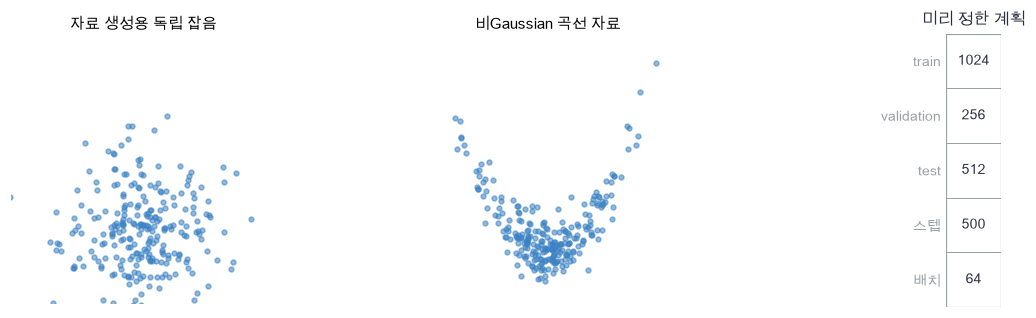

In [34]:
plot_training_plan(plan_noise,plan_data,plan_settings)

🔍 **확인** · 오른쪽 자료의 두 번째 좌표는 첫 번째 좌표의 제곱에 따라 움직입니다. 공분산 하나의 타원보다 더 복잡한 모양입니다. 이 사실이 특정 학습 seed에서 flow가 반드시 이긴다는 보장은 아니므로 실제 heldout 값을 보고합니다.

In [35]:
def banana_data(count,seed):
    """비Gaussian 곡선형 자료. u~N(0,1), x1=.6*(u²−1)+.4*noise. → X:(count,2)."""
    noise = np.random.default_rng(seed).normal(size=(count,2))
    return np.column_stack([noise[:,0],.6*(noise[:,0]**2-1)+.4*noise[:,1]])

In [36]:
def fit_gaussian(X):
    """train만으로 Gaussian 평균과 MLE 공분산을 계산합니다. X:(N,2) → mu:(2,), covariance:(2,2)."""
    mean = X.mean(axis=0)
    centered = X-mean
    covariance = centered.T@centered/len(X)
    return mean,covariance

In [37]:
def gaussian_logpdf(X,mean,covariance):
    """같은 원래 좌표의 Gaussian log density를 Cholesky로 계산합니다. → 관측별 (N,)."""
    factor = np.linalg.cholesky(covariance)
    standardized = np.linalg.solve(factor,(X-mean).T).T
    return -.5*np.sum(standardized**2,axis=1)-np.log(2*np.pi)-np.log(np.diag(factor)).sum()

In [38]:
def adam_step(parameters,gradients,moments,squares,step,learning_rate=.005):
    """층·배열별 Adam 모멘트를 갱신합니다. step은1부터, parameters/state를 제자리 변경합니다."""
    for layer,gradient,first,second in zip(parameters,gradients,moments,squares):
        for key,value in layer.items():
            first[key] = .9*first[key]+.1*gradient[key]
            second[key] = .999*second[key]+.001*gradient[key]**2
            first_hat,second_hat = first[key]/(1-.9**step),second[key]/(1-.999**step)
            value -= learning_rate*first_hat/(np.sqrt(second_hat)+1e-8)

In [39]:
def train_flow(initial,train,validation,schedule,learning_rate=.005):
    """고정 배치 계획으로 NLL을 최소화하고 50스텝마다 validation을 기록합니다. → params, history."""
    # 쓰는 것: flow_logpdf (3절) · flow_loss_gradient (3절)
    parameters = [{key:value.copy() for key,value in layer.items()} for layer in initial]
    moments = [{key:np.zeros_like(value) for key,value in layer.items()} for layer in parameters]
    squares = [{key:np.zeros_like(value) for key,value in layer.items()} for layer in parameters]
    history = []
    for step in range(len(schedule)+1):
        if step%50==0 or step==len(schedule):
            history.append([step,float(-flow_logpdf(validation,parameters).mean())])
        if step==len(schedule):
            break
        loss,dX,gradients = flow_loss_gradient(train[schedule[step]],parameters)
        assert np.isfinite(loss), '학습 NLL이 유한해야 합니다'
        adam_step(parameters,gradients,moments,squares,step+1,learning_rate)
    return parameters,np.asarray(history)

In [40]:
# 쓰는 것: BATCH (4절) · LEARNING_RATE (4절) · STEPS (4절) · TEST_COUNT (4절) · TRAIN_COUNT (4절) · VALID_COUNT (4절) · banana_data (4절) · fit_gaussian (4절) · init_flow (3절) · plan_data (4절)
train_X = banana_data(TRAIN_COUNT,301)
valid_X = banana_data(VALID_COUNT,302)
test_X = banana_data(TEST_COUNT,303)
np.testing.assert_allclose(train_X[:256],plan_data)  # 검산: 설명 그림과 실제 생성식
baseline_mean,baseline_covariance = fit_gaussian(train_X)
np.testing.assert_allclose(gaussian_logpdf(np.zeros((1,2)),np.zeros(2),np.eye(2)),[-np.log(2*np.pi)])  # 검산: 표준정규 원점 밀도
baseline_valid_nll = [-gaussian_logpdf(valid_X,np.zeros(2),np.eye(2)).mean(),-gaussian_logpdf(valid_X,baseline_mean,baseline_covariance).mean()]
initial_parameters = init_flow(300,4,12)
initial_snapshot = [{key:value.copy() for key,value in layer.items()} for layer in initial_parameters]
batch_schedule = np.random.default_rng(304).integers(0,TRAIN_COUNT,size=(STEPS,BATCH))
training_start = perf_counter()
trained_parameters,training_history = train_flow(initial_parameters,train_X,valid_X,batch_schedule,LEARNING_RATE)
print('학습 시간:',round(perf_counter()-training_start,3),'초')
print('실제 parameter 수:',sum(value.size for layer in trained_parameters for value in layer.values()))
for layer,snapshot in zip(initial_parameters,initial_snapshot):
    for key in layer:
        np.testing.assert_array_equal(layer[key],snapshot[key])  # 검산: 학습이 초기 기준선 배열을 바꾸지 않음

학습 시간: 0.117 초
실제 parameter 수: 200


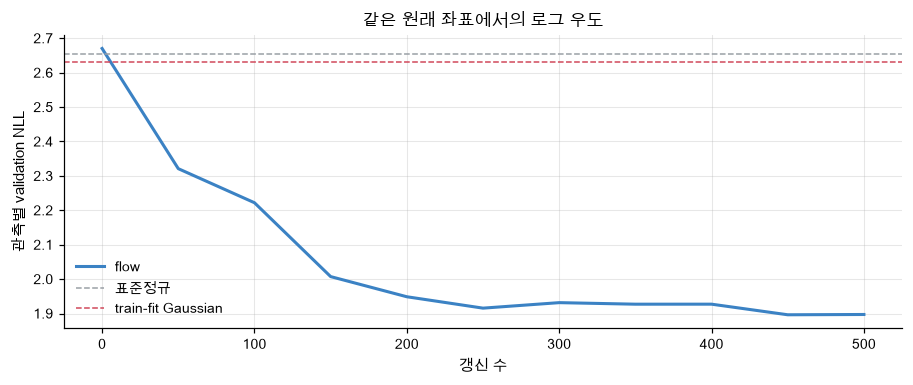

In [41]:
plot_nll_history(training_history,baseline_valid_nll)

🔍 **확인** · 세 곡선·선의 NLL은 같은 validation 관측과 같은 원래 좌표를 사용합니다. 4층 flow는 200개 파라미터를 학습하고 Gaussian은 평균·공분산을 train에서 맞춥니다. 서로 같은 용량이나 연산량의 모델이라는 비교가 아닙니다. 마지막 test에서는 각 모델의 점수 한 번을 계산해 함께 보고합니다.

In [42]:
# 쓰는 것: flow_logpdf (3절) · gaussian_logpdf (4절)
test_standard_logpdf = gaussian_logpdf(test_X,np.zeros(2),np.eye(2))
test_gaussian_logpdf = gaussian_logpdf(test_X,baseline_mean,baseline_covariance)
test_flow_logpdf = flow_logpdf(test_X,trained_parameters)
print('test 관측별 NLL · 표준정규 / train-fit Gaussian / flow:',[-test_standard_logpdf.mean(),-test_gaussian_logpdf.mean(),-test_flow_logpdf.mean()])
density_axis = np.linspace(-4,4,121)
density_xx,density_yy = np.meshgrid(density_axis,density_axis,indexing='xy')
density_points = np.column_stack([density_xx.ravel(),density_yy.ravel()])
gaussian_density = np.exp(gaussian_logpdf(density_points,baseline_mean,baseline_covariance)).reshape(density_xx.shape)
flow_density = np.exp(flow_logpdf(density_points,trained_parameters)).reshape(density_xx.shape)
density_vmax = max(gaussian_density.max(),flow_density.max())

test 관측별 NLL · 표준정규 / train-fit Gaussian / flow: [np.float64(2.6858571650174277), np.float64(2.6681855326524984), np.float64(1.9092067867262554)]


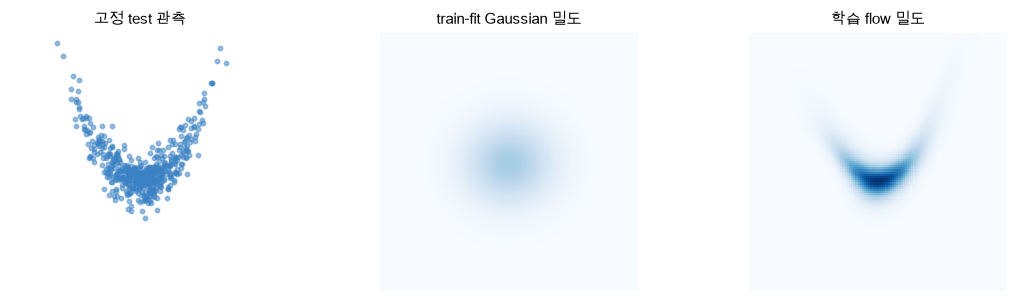

In [43]:
plot_fitted_density(density_xx,density_yy,gaussian_density,flow_density,test_X,density_vmax)

🔍 **확인** · 밀도 그림의 두 모델은 같은 색상 범위를 씁니다. 표시 영역은 $[-4,4]^2$이고 화면 밖의 확률을 0으로 가정하지 않습니다. 점 구름과 높은 밀도 영역을 비교하되, 이 작은 합성 자료의 점수 하나로 일반적인 생성 품질을 단정하지 않습니다.

### ✏️ 연습 4 · 잠재 밀도와 데이터 방향 logdet로 NLL 만들기

`base_logpdf`와 데이터→잠재 `forward_logdet`는 관측별 `(N,)` 배열입니다. 평균 NLL을 한 줄로 계산하세요.

In [44]:
def exercise_flow_nll(base_logpdf,forward_logdet):
    """연습 4: 데이터 로그 밀도는 base+forward logdet, 손실은 음의 평균."""
    ### 구현할 내용: 두 항을 더하고 관측 평균에 마이너스
    raise NotImplementedError
    return loss

In [45]:
def check_flow_nll(candidate):
    """두 관측의 최종 로그 밀도 -1.5와 -3.5를 손계산합니다."""
    np.testing.assert_allclose(candidate(np.array([-2.,-3.]),np.array([.5,-.5])),2.5)  # 검산: -(-1.5-3.5)/2
    print('flow NLL: 손계산과 일치합니다.')

run_check(check_flow_nll,exercise_flow_nll,hint='loss = -np.mean(base_logpdf+forward_logdet)')

☐ exercise_flow_nll: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: loss = -np.mean(base_logpdf+forward_logdet)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = -np.mean(base_logpdf+forward_logdet)
```

</details>

## 🔑 5. 적분 질량과 생성 샘플을 서로 검산합니다

**이 절에서 가져갈 것:** 밀도 적분·역변환 생성·잠재 진단을 연결하되 서로 다른 오차와 구조의 한계를 구분합니다.

그림의 색이 밀도라면 작은 칸의 확률은 **밀도 × 면적**입니다. 상자 $[-R,R]^2$를 축마다 m칸으로 나누고 중앙 $x_{ij}$를 읽는 중점 규칙은

$$h=2R/m,\qquad \int_{[-R,R]^2}p_X(x)dx\ \approx\ h^2\sum_{i,j}p_X(x_{ij})$$

입니다. 같은 상자에서 m을 늘리면 **격자 근사 오차**를 살핍니다. h를 고정하고 R을 늘리면 **경계 밖 질량**을 더 포함합니다. 상자 밖 확률은 격자를 촘촘히 해도 돌아오지 않습니다.

생성은 $z\sim\mathcal N(0,I)$를 뽑아 $x=f^{-1}(z)$로 보냅니다. 생성 방향의 $\ell_{inv}=\log|\det J_{f^{-1}}|$를 썼다면

$$\log p_X(f^{-1}(z))=\log p_Z(z)-\ell_{inv}(z).$$

독립 생성 표본 M개에서 상자 안 비율은 $\widehat q=M^{-1}\sum_m1[x_m\in box]$입니다. 27번처럼 표본 평균에는 밀도를 또 곱하지 않습니다. Monte Carlo 표준오차는 indicator의 표본 SD/$\sqrt M$으로 따로 보고합니다. 이 수치는 격자 수치오차가 아닙니다.

> **용어** · **구적법(quadrature)**은 작은 구간·칸의 값을 더해 적분을 근사하는 방법입니다. **절단(truncation)**은 무한 공간 대신 유한 상자까지만 적분하는 선택입니다. **잠재 진단**은 heldout x를 z로 옮긴 뒤 base 분포와 얼마나 비슷한지 살피는 것입니다.

> **코드** · `np.meshgrid(x,y,indexing='xy')`는 x·y 좌표의 격자를 만듭니다. `ravel()`로 점을 펼쳐 모델에 넣고 `reshape`로 격자로 되돌립니다. `np.all(condition,axis=1)`은 한 표본의 두 좌표가 모두 조건을 만족하는지 확인합니다. `std(ddof=1)`은 표본 SD를 계산합니다.

In [46]:
# 쓰는 것: flow_logpdf (3절) · trained_parameters (4절)
quadrature_centers = np.array([-.75,-.25,.25,.75])
quadrature_xx,quadrature_yy = np.meshgrid(quadrature_centers,quadrature_centers,indexing='xy')
quadrature_points = np.column_stack([quadrature_xx.ravel(),quadrature_yy.ravel()])
quadrature_density = np.exp(flow_logpdf(quadrature_points,trained_parameters)).reshape(4,4)
quadrature_area = .5**2
quadrature_contributions = quadrature_density*quadrature_area
quadrature_summary = np.array([[quadrature_area],[quadrature_contributions.sum()]])
frozen_parameters = [{key:value.copy() for key,value in layer.items()} for layer in trained_parameters]

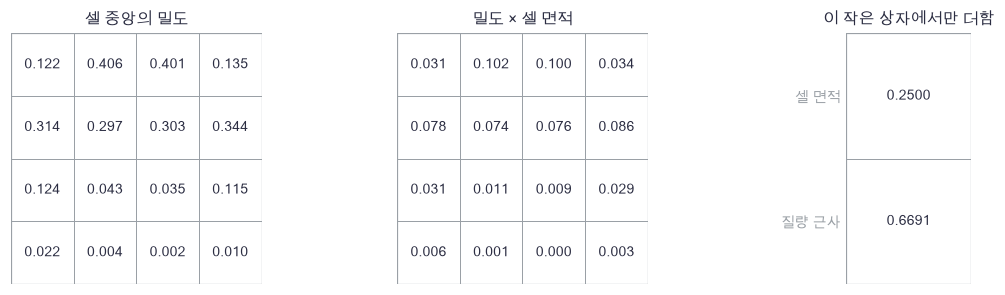

In [47]:
plot_quadrature_cells(quadrature_density,quadrature_contributions,quadrature_summary)

🔍 **확인** · 칸 하나의 면적은 .25이므로 오른쪽 합에는 밀도의 1/4씩 들어갑니다. 이것은 작은 $[-1,1]^2$ 상자의 매우 거친 예시입니다. 합이 1이 아니어도 전체 밀도가 정규화되지 않았다는 뜻은 아닙니다. 아래에서는 알려진 Gaussian 상자 질량으로 구현을 먼저 검사한 뒤 flow에 적용합니다.

In [48]:
def grid_mass(parameters,radius,count):
    """[-R,R]²에서 중점 규칙으로 flow 밀도를 적분합니다. count는 축당 칸 수, 결과는 box 안 질량 근사."""
    # 쓰는 것: flow_logpdf (3절)
    width = 2*radius/count
    centers = -radius+(np.arange(count)+.5)*width
    xx,yy = np.meshgrid(centers,centers,indexing='xy')
    points = np.column_stack([xx.ravel(),yy.ravel()])
    density = np.exp(flow_logpdf(points,parameters))
    return float(density.sum()*width**2)

In [49]:
# 쓰는 것: trained_parameters (4절)
known_gaussian_mass = erf(2/np.sqrt(2))**2
normal_mass_coarse = grid_mass([],2.,80)
normal_mass_fine = grid_mass([],2.,160)
np.testing.assert_allclose(normal_mass_fine,known_gaussian_mass,atol=3e-5)  # 검산: 0층 flow는 표준정규, box 질량은 erf의 제곱
assert abs(normal_mass_fine-known_gaussian_mass) < abs(normal_mass_coarse-known_gaussian_mass), '고정 Gaussian box에서 격자 세분화 오차가 줄어야 합니다'
resolution_counts = [80,160,320]
resolution_masses = [grid_mass(trained_parameters,4.,count) for count in resolution_counts]
resolution_table = np.column_stack([resolution_counts,resolution_masses])
assert abs(resolution_masses[-1]-resolution_masses[-2]) < 1e-4, '고정 box의 두 촘촘한 격자 질량이 가까워야 합니다'
print('Gaussian box 참값/중점근사:',known_gaussian_mass,normal_mass_fine)
print('R=4 고정 해상도 변화:',resolution_table)

Gaussian box 참값/중점근사: 0.9110697462219214 0.9110804823834925
R=4 고정 해상도 변화: [[ 80.           0.99690013]
 [160.           0.99689848]
 [320.           0.99689807]]


In [50]:
# 쓰는 것: TEST_COUNT (4절) · flow_forward (3절) · flow_inverse (3절) · flow_logpdf (3절) · test_X (4절) · trained_parameters (4절)
new_latent = np.random.default_rng(306).normal(size=(TEST_COUNT,2))
generated_X,generated_inverse_ld = flow_inverse(new_latent,trained_parameters)
latent_test,latent_test_ld,_ = flow_forward(test_X,trained_parameters)
generated_logpdf = flow_logpdf(generated_X,trained_parameters)
base_new_logpdf = -.5*np.sum(new_latent**2,axis=1)-np.log(2*np.pi)
np.testing.assert_allclose(generated_logpdf,base_new_logpdf-generated_inverse_ld,atol=1e-10)  # 검산: 생성 방향 logdet는 빼야 함
back_to_latent = flow_forward(generated_X,trained_parameters)[0]
np.testing.assert_allclose(back_to_latent,new_latent,atol=1e-11)  # 검산: 학습된 생성의 z→x→z 왕복
latent_mean = latent_test.mean(axis=0)
latent_centered = latent_test-latent_mean
latent_covariance = latent_centered.T@latent_centered/len(latent_test)
print('heldout 잠재 평균:',latent_mean)
print('heldout 잠재 공분산:',latent_covariance)
print('heldout 잠재 평균 제곱반지름:',np.mean(np.sum(latent_test**2,axis=1)),'· base의 기대값은2')

heldout 잠재 평균: [-0.03295693  0.0413674 ]
heldout 잠재 공분산: [[ 0.9525586  -0.11797982]
 [-0.11797982  0.98819166]]
heldout 잠재 평균 제곱반지름: 1.9435476795301185 · base의 기대값은2


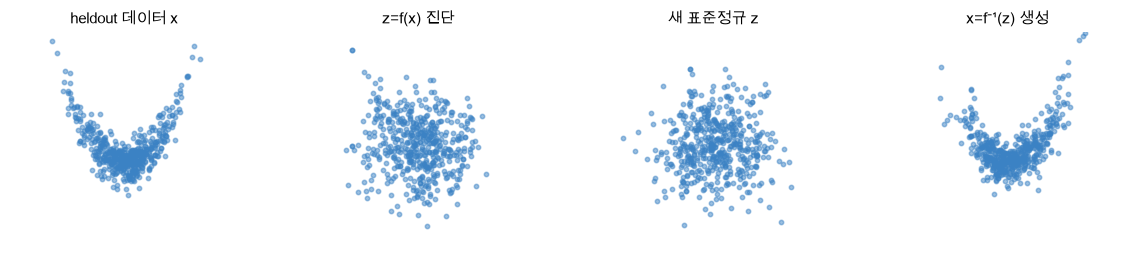

In [51]:
plot_generation_diagnostics(test_X,latent_test,new_latent,generated_X)

🔍 **확인** · 왼쪽 두 패널은 heldout 데이터→잠재이고 오른쪽 두 패널은 **새 독립 base 표본→생성**입니다. 생성 점은 훈련 관측을 고른 것이 아닙니다. 평균이 0·공분산이 I에 가깝더라도 잠재 분포 전체가 표준정규라는 증명은 아닙니다. 같은 표시 범위 ±4에서 산점도를 보고 NLL·부피 검산도 함께 읽습니다.

In [52]:
# 쓰는 것: flow_inverse (3절) · frozen_parameters (5절) · grid_mass (5절) · trained_parameters (4절)
box_latent = np.random.default_rng(307).normal(size=(20000,2))
box_samples,_ = flow_inverse(box_latent,trained_parameters)
box_radii = [2.,4.,6.]
box_records = []
for radius in box_radii:
    count = int(2*radius/.05)
    grid_probability = grid_mass(trained_parameters,radius,count)
    inside = np.all(np.abs(box_samples)<=radius,axis=1)
    mc_probability = inside.mean()
    mc_standard_error = inside.std(ddof=1)/np.sqrt(len(inside))
    box_records.append([radius,grid_probability,mc_probability,mc_standard_error])
box_table = np.asarray(box_records)
assert np.all(np.diff(box_table[:,1])>0), '같은 간격에서 box를 넓히면 이 예제의 포함 질량이 늘어야 합니다'
np.testing.assert_allclose(box_table[-1,1],1.,atol=2e-3)  # 검산: 넓은 box의 수치 질량이1에 가까움
for layer,snapshot in zip(trained_parameters,frozen_parameters):
    for key in layer:
        np.testing.assert_array_equal(layer[key],snapshot[key])  # 검산: 적분·생성·진단이 모델을 갱신하지 않음
print('동일 간격의 box 확대와 독립 생성 Monte Carlo:',box_table)

동일 간격의 box 확대와 독립 생성 Monte Carlo: [[2.00000000e+00 9.56069361e-01 9.56900000e-01 1.43604408e-03]
 [4.00000000e+00 9.96898480e-01 9.96150000e-01 4.37913763e-04]
 [6.00000000e+00 9.99936192e-01 1.00000000e+00 0.00000000e+00]]


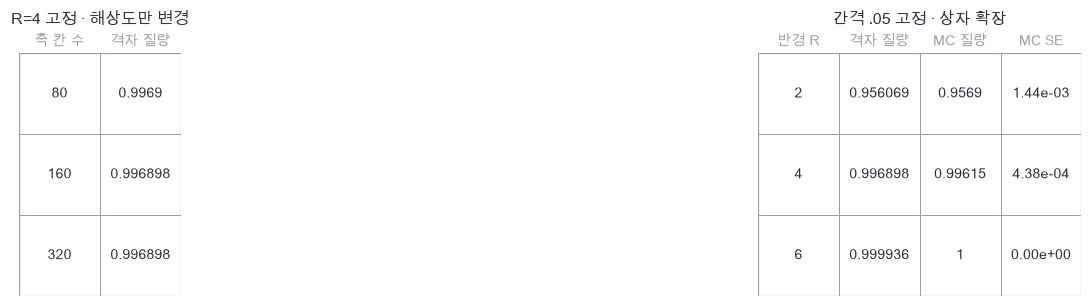

In [53]:
plot_mass_checks(resolution_table,box_table)

🔍 **확인** · 왼쪽 표는 같은 상자 안에서 해상도만 늘렸습니다. 오른쪽은 같은 간격 .05에서 더 넓은 공간을 적분합니다. 유한 box의 격자 질량은 1에 가까워질 수 있지만 그 자체가 무한 공간 적분의 엄밀한 증명은 아닙니다. 이 모델의 정규화는 가역 변수변환 공식에서 오며, 격자와 Monte Carlo는 구현을 교차 확인하는 수치 진단입니다. MC에서 밖으로 나간 점이 0개여도 상자 밖 확률이 정확히 0이라는 뜻은 아닙니다. 이 경우 경험 표준오차도 0으로 계산되지만 참 오차가 0이라는 보장은 아닙니다.

**구조의 한계도 남습니다.** 모든 유한 위치에서 표준정규 밀도는 양수이고, 이 모델의 가역 변환은 차원을 유지하며 Jacobian이 0이 되지 않습니다. 따라서 정확히 확률이 0인 빈 영역으로 분리된 지지집합이나 더 낮은 차원의 곡선 위에만 놓인 분포를 그대로 만들지는 못합니다. 여러 봉우리의 밀도는 근사할 수 있으므로 이것을 “다봉 분포는 불가능”으로 읽지는 않습니다. 제한된 층 수·은닉 폭·bounded scale은 학습할 모양과 꼬리에도 제약을 줍니다. heldout 점수가 좋아도 이 제약이나 분포 밖 성능이 사라지지는 않습니다.

### ✏️ 연습 5 · 2D 밀도 격자를 질량으로 바꾸기

`density:(rows,columns)`는 각 셀 중앙의 밀도입니다. x 방향 간격 `dx`, y 방향 간격 `dy`를 곱해 이 유한 상자의 질량 근사를 구하세요.

In [54]:
def exercise_grid_mass(density,dx,dy):
    """연습 5: 2D 중점 적분 sum(density)*dx*dy. → scalar mass."""
    ### 구현할 내용: 각 셀 밀도에 셀 면적을 곱해 합하기
    raise NotImplementedError
    return mass

In [55]:
def check_grid_mass(candidate):
    """두 행 세 열, 서로 다른 x/y 간격의 면적을 손계산합니다."""
    np.testing.assert_allclose(candidate(np.ones((2,3))*.5,.2,.5),.3)  # 검산: 6*.5*.2*.5
    np.testing.assert_allclose(candidate(np.array([[1.,2.],[3.,4.]]),.1,.2),.2)  # 검산: (1+2+3+4)*.02
    print('2D 질량: 손계산과 일치합니다.')

run_check(check_grid_mass,exercise_grid_mass,hint='mass = density.sum()*dx*dy')

☐ exercise_grid_mass: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: mass = density.sum()*dx*dy


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mass = density.sum()*dx*dy
```

</details>

## ✏️ 전체 연결 연습 A–D

층·관측 축, scale의 도함수, 생성 방향, 단위 변경을 한두 줄씩 다시 확인합니다.

### ✏️ 연습 A · 층을 더하되 관측은 남기기

`layer_logdets:(L,N)`의 행은 층, 열은 관측입니다. 층을 합쳐 관측별 전체 logdet `(N,)`를 구하세요. swap의 0행도 합에 포함해도 됩니다.

In [56]:
def exercise_total_logdet(layer_logdets):
    """연습 A: L개 층을 합쳐 N개 관측의 logdet를 남깁니다."""
    ### 구현할 내용: 층 축0의 합
    raise NotImplementedError
    return total

In [57]:
def check_total_logdet(candidate):
    """관측별로 더하고 swap의0항도 처리하는지 손계산합니다."""
    values = np.array([[.2,-.3],[0.,0.],[-.5,.7]])
    np.testing.assert_allclose(candidate(values),[-.3,.4])  # 검산: .2-.5, -.3+.7
    print('층별 logdet 합: 손계산과 일치합니다.')

run_check(check_total_logdet,exercise_total_logdet,hint='total = layer_logdets.sum(axis=0)')

☐ exercise_total_logdet: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: total = layer_logdets.sum(axis=0)


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
total = layer_logdets.sum(axis=0)
```

</details>

### ✏️ 연습 B · bounded log scale까지 미분하기

`s=.8*tanh(raw)`이고 상류 기울기 `ds`가 주어집니다. raw로 돌아갈 미분을 쓰세요.

In [58]:
def exercise_bounded_scale_gradient(raw,ds):
    """연습 B: .8*tanh(raw)의 도함수에 upstream ds를 곱합니다."""
    ### 구현할 내용: .8*(1-tanh(raw)^2)*ds
    raise NotImplementedError
    return gradient

In [59]:
def check_bounded_scale_gradient(candidate):
    """raw0과 tanh(raw)=.5의 도함수를 손계산합니다."""
    actual = candidate(np.array([0.,np.arctanh(.5)]),np.array([2.,-1.]))
    np.testing.assert_allclose(actual,[1.6,-.6])  # 검산: .8*1*2, .8*.75*(-1)
    print('bounded scale 미분: 손계산과 일치합니다.')

run_check(check_bounded_scale_gradient,exercise_bounded_scale_gradient,hint='gradient = .8*(1-np.tanh(raw)**2)*ds')

☐ exercise_bounded_scale_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: gradient = .8*(1-np.tanh(raw)**2)*ds


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = .8*(1-np.tanh(raw)**2)*ds
```

</details>

### ✏️ 연습 C · 생성 방향 logdet의 부호

새 base 표본의 `base_logpdf`와 **잠재→데이터** 역변환의 `inverse_logdet`가 주어집니다. 생성한 x의 log density를 쓰세요.

In [60]:
def exercise_generated_logpdf(base_logpdf,inverse_logdet):
    """연습 C: 생성 부피를 보정한 데이터 log density. 입력·출력:(N,)."""
    ### 구현할 내용: base에서 inverse logdet 빼기
    raise NotImplementedError
    return logpdf

In [61]:
def check_generated_logpdf(candidate):
    """생성 부피가 커질 때 밀도가 낮아지는지 손계산합니다."""
    np.testing.assert_allclose(candidate(np.array([-2.,-2.]),np.array([.7,-.3])),[-2.7,-1.7])  # 검산: -2-.7, -2+.3
    print('생성 방향 밀도: 손계산과 일치합니다.')

run_check(check_generated_logpdf,exercise_generated_logpdf,hint='logpdf = base_logpdf-inverse_logdet')

☐ exercise_generated_logpdf: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: logpdf = base_logpdf-inverse_logdet


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
logpdf = base_logpdf-inverse_logdet
```

</details>

### ✏️ 연습 D · 좌표 단위를 바꾸어도 같은 분포를 뜻하려면

`y_j=scale_j*x_j`로 단위를 바꿉니다. `logpdf_x:(N,)`와 0이 아닌 좌표별 `scales:(D,)`를 받아 y좌표의 밀도로 보정하세요.

In [62]:
def exercise_change_units(logpdf_x,scales):
    """연습 D: 좌표별 단위 변환의 logabsdet를 빼기. → 관측별 log density."""
    assert np.all(scales!=0), '각 좌표의 scale이0이 아니어야 합니다'
    ### 구현할 내용: 각 좌표 log|scale|의 합을 모든 관측에서 빼기
    raise NotImplementedError
    return logpdf_y

In [63]:
def check_change_units(candidate):
    """3차원의 부피배율2와 두 관측에 같은 상수를 보정하는지 확인합니다."""
    values = np.array([-1.,-3.])
    np.testing.assert_allclose(candidate(values,np.array([2.,-.5,2.])),values-np.log(2))  # 검산: |2*(-.5)*2|=2
    print('좌표 단위 밀도 보정: 손계산과 일치합니다.')

run_check(check_change_units,exercise_change_units,hint='logpdf_y = logpdf_x-np.log(np.abs(scales)).sum()')

☐ exercise_change_units: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: logpdf_y = logpdf_x-np.log(np.abs(scales)).sum()


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
logpdf_y = logpdf_x-np.log(np.abs(scales)).sum()
```

</details>

### ✏️ 준비도 질문 · 네 가지를 따로 확인합니다

- **설명:** 같은 확률을 더 넓은 공간에 옮기면 밀도 높이가 왜 달라지나요? conditioner가 가역이지 않아도 coupling은 왜 가역인가요? → 1·2절
- **수식:** 데이터→잠재와 생성 방향의 logdet 부호, swap의 determinant 부호와 log 절댓값, 층별 logdet 합, 2D base 정규화 상수를 쓸 수 있나요? → 1–3절
- **구현:** 값 경로와 logdet 경로를 모두 포함해 s,t·신경망·유지 좌표까지 backward를 연결할 수 있나요? 실제 NLL의 모든 파라미터·입력 중심차분을 다시 할 수 있나요? → 2·3절, 연습 A·B·C
- **변형 검산:** 층 수를 홀수로 바꾸어 왕복·Jacobian을 검사하고, 좌표 단위가 달라질 때 밀도를 보정할 수 있나요? 고정 box 해상도 변화·같은 간격의 box 확대·Monte Carlo SE를 구분하나요? → 3–5절, 연습 D

### 📎 다음 연결

27번의 재매개화처럼 잡음을 고정하고 생성 경로를 미분할 수도 있지만, 이 실험은 관측의 정확한 NLL을 학습했습니다. 29번의 critic 목적이나 25번의 ELBO와 목적이 다릅니다. 37 생성 모델 평가에서는 로그 밀도·샘플·고정 평가 조건을 함께 비교해 보세요. 새 설정을 평가 결과로 고르면 기존 test는 개발 자료가 된다는 원칙도 같습니다.